# Síntese da análise exploratória do genoma de *Colletotrichum abscissum* Ca142

**Montagem:** GCA_023376855.1 ·

**Linhagem:** Ca142 ·

**Anotação:** 15.499 genes codificadores de proteína (MAKER)

Este caderno fecha a análise exploratória. Ele não calcula nada de novo sobre as sequências: **reúne** as tabelas
dos cadernos anteriores, confere os números com o que foi publicado e monta a **tabela final de genes**, com os
alertas de qualidade de cada modelo.

1. Configuração
2. Ficha do genoma
3. Comparação com os dados publicados
4. Tabela final de genes e alertas de qualidade
5. Como consultar a tabela: a succinato desidrogenase (SDH) e a maquinaria de RNAi
6. Conclusões da análise exploratória
7. Próxima fase

**Pré-requisitos:** `03_estrutura_ca142.ipynb` (obrigatório). Os resultados de `04_composicao_ca142.ipynb` e
`05_completude_busco_ca142.ipynb` são incluídos se existirem; sem eles, as colunas correspondentes ficam vazias.

**Nota da revisão:** as seções 4.1, 4.2, 5.1 e 5.2 têm células novas ou alteradas, ainda sem saída. Os números
citados nos textos dessas seções foram calculados com as tabelas já salvas; rode o caderno de novo para ver as
saídas.

## 1. Configuração

A função `ler` carrega uma tabela de `data/processed/`. Para as tabelas opcionais, devolve `None` e avisa quando o
arquivo não existe, em vez de interromper o caderno.

In [11]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from Bio import SeqIO

ACCESSION = "GCA_023376855.1"

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_DADOS = RAIZ / "data" / "raw" / "ca142" / "ncbi_dataset" / "data" / ACCESSION
DIR_PROC = RAIZ / "data" / "processed"
DIR_RES = RAIZ / "results"
DIR_FIG = DIR_RES / "figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)
ARQ_CDS = DIR_DADOS / "cds_from_genomic.fna"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)

AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.figsize": (7.5, 3.4), "figure.dpi": 110, "savefig.dpi": 200,
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "xtick.labelsize": 9, "ytick.labelsize": 9, "font.size": 10,
})

def fmt(n):
    return f"{n:,.0f}".replace(",", ".")

def ler(nome, obrigatoria=False, origem=""):
    caminho = DIR_PROC / nome
    if caminho.exists():
        return pd.read_csv(caminho, sep="\t")
    if obrigatoria:
        raise FileNotFoundError(f"{nome} não encontrado. Rode antes o caderno {origem}.")
    print(f"Aviso: {nome} não encontrado (caderno {origem} ainda não executado); essa parte fica vazia.")
    return None

scaffolds = ler("ca142_scaffolds.tsv", True, "03_estrutura_ca142")
genes = ler("ca142_genes.tsv", True, "03_estrutura_ca142")
introns = ler("ca142_introns.tsv", True, "03_estrutura_ca142")
contexto = ler("ca142_genes_contexto.tsv", origem="04_composicao_ca142")
janelas = ler("ca142_janelas_10kb.tsv", origem="04_composicao_ca142")
janelas_rip = ler("ca142_janelas_rip_1kb.tsv", origem="04_composicao_ca142")
blocos_rip = ler("ca142_blocos_rip.tsv", origem="04_composicao_ca142")
busco = ler("ca142_busco.tsv", origem="05_completude_busco_ca142")
genes_busco = ler("ca142_genes_busco.tsv", origem="05_completude_busco_ca142")

if "n_introns_nc" not in genes.columns:
    raise RuntimeError("ca142_genes.tsv está desatualizado: rode de novo o caderno 03 (versão revisada).")
print(f"{len(scaffolds)} scaffolds · {fmt(len(genes))} genes · {fmt(len(introns))} íntrons")

423 scaffolds · 15.499 genes · 27.371 íntrons


## 2. Ficha do genoma

Recalculamos os números principais a partir das tabelas salvas e os reunimos em um só lugar. As linhas marcadas com
"—" dependem de cadernos ainda não executados.

In [12]:
def n50_l50(tamanhos):
    t = np.sort(np.asarray(tamanhos))[::-1]
    i = int(np.searchsorted(np.cumsum(t), t.sum() / 2))
    return int(t[i]), i + 1

total = int(scaffolds["tamanho"].sum())
n50, l50 = n50_l50(scaffolds["tamanho"])
gc = 100 * (scaffolds["G"].sum() + scaffolds["C"].sum()) / scaffolds[["A", "C", "G", "T"]].sum().sum()
completos = genes[~genes["parcial"]]
introns_comp = introns[~introns["parcial"]]
hipotetica = genes["produto"].fillna("").str.contains("hypothetical|uncharacterized", case=False)

ficha = {
    "MONTAGEM": "",
    "Tamanho": f"{fmt(total)} pb",
    "Scaffolds": fmt(len(scaffolds)),
    "N50 / L50": f"{fmt(n50)} pb / {l50}",
    "GC": f"{gc:.2f}%",
    "Bases N": fmt(scaffolds["N"].sum()),
    "ANOTAÇÃO": "",
    "Genes codificadores": fmt(len(genes)),
    "Genes parciais": f"{fmt(genes['parcial'].sum())} ({100 * genes['parcial'].mean():.1f}%)",
    "Densidade": f"{len(genes) / (total / 1e6):.0f} genes por Mb",
    "Éxons por gene (média / mediana)": f"{completos['n_exons'].mean():.2f} / {completos['n_exons'].median():.0f}",
    "Genes sem íntrons": f"{100 * (completos['n_exons'] == 1).mean():.1f}%",
    "Gene (mediana)": f"{fmt(completos['tam_gene'].median())} pb",
    "Proteína (média / mediana)": f"{completos['tam_proteina'].mean():.0f} / {completos['tam_proteina'].median():.0f} aa",
    "Íntron (média / mediana)": f"{introns_comp['tamanho'].mean():.0f} / {introns_comp['tamanho'].median():.0f} pb",
    "Íntrons canônicos": f"{100 * introns_comp['canonico'].mean():.1f}%",
    "Proteínas hipotéticas": f"{100 * hipotetica.mean():.1f}%",
    "COMPOSIÇÃO (caderno 04)": "",
    "Genoma em janelas ricas em AT": "—",
    "Janelas de 1 kb compatíveis com RIP": "—",
    "Blocos com assinatura de RIP": "—",
    "COMPLETUDE (caderno 05)": "",
    "BUSCOs completos (S + D)": "—",
    "BUSCOs fragmentados / ausentes": "—",
}
if janelas is not None:
    ficha["Genoma em janelas ricas em AT"] = f"{100 * janelas.loc[janelas['rica_at'], 'tamanho'].sum() / janelas['tamanho'].sum():.1f}%"
if janelas_rip is not None:
    ficha["Janelas de 1 kb compatíveis com RIP"] = f"{100 * janelas_rip['rip'].mean():.2f}%"
if blocos_rip is not None:
    ficha["Blocos com assinatura de RIP"] = f"{len(blocos_rip)} ({fmt(blocos_rip['tamanho'].sum())} pb)"
if busco is not None:
    st = busco.drop_duplicates("busco_id")["status"].value_counts(normalize=True).mul(100)
    ficha["BUSCOs completos (S + D)"] = f"{st.get('Complete', 0) + st.get('Duplicated', 0):.1f}%"
    ficha["BUSCOs fragmentados / ausentes"] = f"{st.get('Fragmented', 0):.1f}% / {st.get('Missing', 0):.1f}%"

pd.Series(ficha, name="Ca142").to_frame()

,Ca142
MONTAGEM,
Tamanho,54.001.896 pb
Scaffolds,423
N50 / L50,321.765 pb / 46
GC,51.12%
Bases N,846
ANOTAÇÃO,
Genes codificadores,15.499
Genes parciais,215 (1.4%)
Densidade,287 genes por Mb


**Resultado:** a ficha está completa, com os resultados dos seis cadernos. Em uma frase: um genoma de 54 Mb em 423
scaffolds, com 15.499 genes compactos, uma anotação 98,3% completa para os genes conservados, e 5,5% das bases em
blocos ricos em AT com assinatura de RIP.

## 3. Comparação com os dados publicados

### 3.1 Montagem e número de genes

Uma análise exploratória começa por **reproduzir** o que já foi publicado: se os nossos números batem com os do NCBI
e do artigo (Goulin et al., 2023, *Phytopathology* 113:104–107), sabemos que estamos olhando para os mesmos dados e
que o nosso código está certo.

In [13]:
publicado = {"Tamanho (pb)": 54_001_896, "Scaffolds": 423, "N50 (pb)": 321_765, "L50": 46,
             "Maior scaffold (pb)": 2_556_205, "GC (%)": 51.10, "Genes codificadores": 15_499}
calculado = {"Tamanho (pb)": total, "Scaffolds": len(scaffolds), "N50 (pb)": n50, "L50": l50,
             "Maior scaffold (pb)": int(scaffolds["tamanho"].max()), "GC (%)": round(gc, 2),
             "Genes codificadores": len(genes)}
mostrar = lambda v: f"{v:.2f}".replace(".", ",") if isinstance(v, float) else fmt(v)
comp = pd.DataFrame({
    "publicado": {k: mostrar(v) for k, v in publicado.items()},
    "calculado aqui": {k: mostrar(v) for k, v in calculado.items()},
    "confere": {k: "sim" if abs(publicado[k] - calculado[k]) <= 0.05 else "NÃO" for k in publicado},
})
comp

,publicado,calculado aqui,confere
Tamanho (pb),54.001.896,54.001.896,sim
Scaffolds,423,423,sim
N50 (pb),321.765,321.765,sim
L50,46,46,sim
Maior scaffold (pb),2.556.205,2.556.205,sim
GC (%),"51,10","51,12",sim
Genes codificadores,15.499,15.499,sim


**Resultado:** as sete linhas conferem. Os arquivos analisados são os mesmos descritos no NCBI e no artigo, e os
cálculos básicos estão certos. O GC admite uma diferença de até 0,05 ponto, porque o artigo arredonda para 51,10% e
o valor calculado é 51,12%.

### 3.2 Estrutura dos genes: Ca142 e IMI 504890

Não há outra anotação da Ca142 para comparar, mas o portal **MycoCosm** (JGI) publica as estatísticas da anotação da
linhagem IMI 504890, a referência RefSeq da espécie. Os valores da IMI 504890 abaixo foram copiados do portal
(página *Colletotrichum abscissum IMI 504890 — Info*); os da Ca142 são calculados aqui, com todos os genes.

As duas anotações vêm de **pipelines diferentes**, então diferenças pequenas não devem ser interpretadas como
biologia.

In [14]:
mycocosm = {"Genes": 17_280, "Gene: média (pb)": 1459, "Gene: mediana (pb)": 1221,
            "Proteína: média (aa)": 430, "Proteína: mediana (aa)": 356,
            "Éxons por gene: média": 2.66, "Éxons por gene: mediana": 2,
            "Íntron: média (pb)": 104, "Íntron: mediana (pb)": 66}
ca142 = {"Genes": len(genes), "Gene: média (pb)": genes["tam_gene"].mean(), "Gene: mediana (pb)": genes["tam_gene"].median(),
         "Proteína: média (aa)": genes["tam_proteina"].mean(), "Proteína: mediana (aa)": genes["tam_proteina"].median(),
         "Éxons por gene: média": genes["n_exons"].mean(), "Éxons por gene: mediana": genes["n_exons"].median(),
         "Íntron: média (pb)": introns["tamanho"].mean(), "Íntron: mediana (pb)": introns["tamanho"].median()}
comp_estrutura = pd.DataFrame({"Ca142 (calculado)": ca142, "IMI 504890 (MycoCosm)": mycocosm})
comp_estrutura["Ca142 (calculado)"] = comp_estrutura["Ca142 (calculado)"].round(2)
comp_estrutura["diferença (%)"] = (100 * (comp_estrutura["Ca142 (calculado)"] / comp_estrutura["IMI 504890 (MycoCosm)"] - 1)).round(1)
comp_estrutura

,Ca142 (calculado),IMI 504890 (MycoCosm),diferença (%)
Genes,15499.00,17280.00,-10.3
Gene: média (pb),1547.53,1459.00,6.1
Gene: mediana (pb),1334.00,1221.00,9.3
Proteína: média (aa),463.24,430.00,7.7
Proteína: mediana (aa),394.00,356.00,10.7
Éxons por gene: média,2.77,2.66,4.1
Éxons por gene: mediana,2.00,2.00,0.0
Íntron: média (pb),87.67,104.00,-15.7
Íntron: mediana (pb),63.00,66.00,-4.5


**Resultado:** as duas anotações descrevem a mesma arquitetura de genes.

- **Quase iguais:** os éxons por gene (2,77 e 2,66, com mediana de 2 nas duas) e a mediana dos íntrons (63 e 66 pb).
- **A Ca142 tem 10% menos genes** (15.499 contra 17.280), **e genes mais longos:** de 6% a 9% no gene e de 8% a 11%
  na proteína.
- **Os íntrons da Ca142 são 16% menores na média** (88 contra 104 pb), embora a mediana seja quase a mesma. A
  diferença está na cauda: a anotação da IMI 504890 provavelmente tem mais íntrons longos.

Esse conjunto de diferenças é o que se espera quando duas anotações diferem no rigor: uma anotação que aceita mais
predições curtas tem **mais genes e genes menores**. Não é evidência de que a IMI 504890 tenha 1.800 genes a mais
que a Ca142. Para comparar o conteúdo gênico das duas linhagens seria preciso anotá-las com o mesmo método ou
comparar os genes um a um por similaridade.

## 4. Tabela final de genes e alertas de qualidade

Juntamos, em uma linha por gene, tudo o que os cadernos anteriores produziram, e marcamos quatro **alertas** sobre o
modelo de gene:

| Alerta | Critério | Por que desconfiar | Origem |
|---|---|---|---|
| `parcial` | sem códon de início ou de parada | a sequência do gene está incompleta | caderno 03, seção 3.2 |
| `intron_nao_canonico` | pelo menos um íntron fora das regras GT–AG, GC–AG, AT–AC | junção provavelmente mal posicionada | caderno 03, seção 5.5 |
| `intron_muito_curto` | pelo menos um íntron com menos de 40 pb | íntron improvável em fungos filamentosos | caderno 03, seção 5.3 |
| `proteina_curta` | proteína com menos de 50 aminoácidos | pode ser fragmento ou predição espúria | caderno 03, seção 5.2 |

Um alerta não quer dizer que o gene não existe. Quer dizer que **a sequência anotada pode não ser a real**, e que
vale conferir o modelo antes de usá-lo (por exemplo, comparando com a montagem LW-VAL-2A ou com dados de RNA-seq).

A tabela também traz o **contexto** de cada gene (caderno 04) e a correspondência com os **BUSCOs** (caderno 05),
quando disponíveis.

In [15]:
final = genes.copy()
final["hipotetica"] = hipotetica
final["intron_nao_canonico"] = final["n_introns_nc"] > 0
final["intron_muito_curto"] = final["menor_intron"] < 40          # genes sem íntrons ficam como False
final["proteina_curta"] = final["tam_proteina"] < 50

ALERTAS = ["parcial", "intron_nao_canonico", "intron_muito_curto", "proteina_curta"]
final["n_alertas"] = final[ALERTAS].sum(axis=1)

if contexto is not None:
    final = final.merge(contexto, on="locus_tag", how="left")
else:
    for coluna in ["gc3", "gc_janela", "rica_at", "em_bloco_rip", "dist_gene_anterior", "dist_gene_seguinte"]:
        final[coluna] = pd.NA
if genes_busco is not None:
    final = final.merge(genes_busco[["locus_tag", "busco_id", "busco_status"]], on="locus_tag", how="left")
else:
    final["busco_id"] = pd.NA
    final["busco_status"] = pd.NA

resumo_alertas = final[ALERTAS].sum().rename("genes").to_frame()
resumo_alertas.loc["pelo menos um alerta"] = (final["n_alertas"] > 0).sum()
resumo_alertas.loc["nenhum alerta"] = (final["n_alertas"] == 0).sum()
resumo_alertas["% dos genes"] = (100 * resumo_alertas["genes"] / len(final)).round(1)
resumo_alertas

,genes,% dos genes
parcial,215,1.4
intron_nao_canonico,1113,7.2
intron_muito_curto,379,2.4
proteina_curta,152,1.0
pelo menos um alerta,1568,10.1
nenhum alerta,13931,89.9


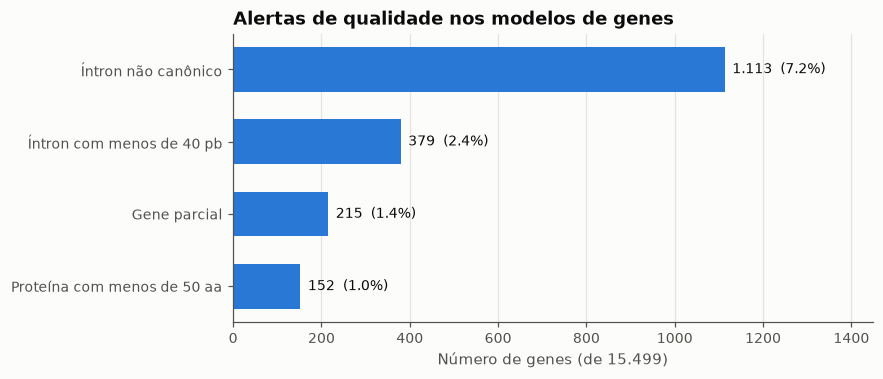

In [16]:
ROTULOS = {"parcial": "Gene parcial", "intron_nao_canonico": "Íntron não canônico",
           "intron_muito_curto": "Íntron com menos de 40 pb", "proteina_curta": "Proteína com menos de 50 aa"}
dados = resumo_alertas.loc[ALERTAS].rename(index=ROTULOS).sort_values("genes")

fig, ax = plt.subplots()
ax.barh(dados.index, dados["genes"], color=AZUL, height=0.62)
for i, (n, p) in enumerate(zip(dados["genes"], dados["% dos genes"])):
    ax.annotate(f"{fmt(n)}  ({p:.1f}%)", (n, i), xytext=(5, 0), textcoords="offset points",
                va="center", color=TINTA, fontsize=9)
ax.set_xlim(0, dados["genes"].max() * 1.3 + 1)
ax.set_xlabel(f"Número de genes (de {fmt(len(final))})")
ax.set_title("Alertas de qualidade nos modelos de genes")
ax.grid(axis="y", visible=False)
fig.savefig(DIR_FIG / "06_alertas.png", bbox_inches="tight")
plt.show()

**Resultado: 90% dos modelos de genes passam em todas as verificações.**

| Alerta | Genes | % |
|---|---|---|
| Íntron não canônico | 1.113 | 7,2% |
| Íntron com menos de 40 pb | 379 | 2,4% |
| Gene parcial | 215 | 1,4% |
| Proteína com menos de 50 aa | 152 | 1,0% |
| **Pelo menos um alerta** | **1.568** | **10,1%** |
| **Nenhum alerta** | **13.931** | **89,9%** |

- **Os alertas se sobrepõem:** as quatro linhas somam 1.859, mas são 1.568 genes. Dos que têm alerta, 1.279 têm um
  só, 287 têm dois e 2 têm três.
- **Íntron curto e íntron não canônico andam juntos:** 280 dos 379 genes com íntron de menos de 40 pb também têm
  íntron não canônico. É o mesmo artefato visto no caderno 03.
- **As proteínas curtas são quase todas hipotéticas** (97%), e nenhuma corresponde a um BUSCO. Isso reforça a
  suspeita de que boa parte delas são predições espúrias.
- **Os alertas não escolhem tipo de gene:** a proporção de proteínas hipotéticas é quase a mesma com alerta (55%) e
  sem alerta (53%).

Os 13.931 genes sem alerta são o ponto de partida para a busca de alvos.

### 4.1 Do conjunto completo aos genes mais confiáveis

A tabela abaixo aplica os filtros em sequência e mostra quantos genes sobram em cada passo. Os dois últimos passos
dependem dos cadernos 04 e 05.

**Critérios revistos depois dos resultados.** A primeira versão desta célula também excluía os genes em janelas
ricas em AT e os genes sem nome de produto. Os resultados mostraram que esses dois filtros descartavam genes bons:

- a marca `rica_at` é da **janela de 10 kb**, não do gene, e o limiar inclui janelas de transição cheias de genes
  normais (caderno 04). A subunidade SdhC da succinato desidrogenase, por exemplo, tem modelo sem alertas e é
  conservada, mas ficava de fora por estar a 2,4 kb de um bloco. O critério agora é mais específico: o gene **tocar**
  um bloco com assinatura de RIP;
- **ser hipotética é uma limitação da anotação, não do modelo de gene.** Das 8.229 proteínas hipotéticas, 1.967 são
  conservadas em cópia única (caderno 05). O nome deixou de ser um filtro e passou a ser só uma informação: a última
  linha da tabela.

In [17]:
passos = [("Todos os genes anotados", pd.Series(True, index=final.index)),
          ("… sem alertas de modelo", final["n_alertas"] == 0)]
if contexto is not None:
    passos.append(("… que não tocam blocos com assinatura de RIP", ~final["em_bloco_rip"].eq(True)))
if genes_busco is not None:
    passos.append(("… conservados em cópia única (BUSCO completo)", final["busco_status"] == "Complete"))

filtro = pd.Series(True, index=final.index)
linhas = []
for nome, condicao in passos:
    filtro &= condicao
    linhas.append({"filtro": nome, "genes": int(filtro.sum()), "% do total": round(100 * filtro.mean(), 1)})
final["conjunto_confiavel"] = filtro

# Informação, não filtro: quantos genes do conjunto têm nome de produto
com_nome = filtro & ~final["hipotetica"]
linhas.append({"filtro": "    dos quais com função anotada (não hipotética)", "genes": int(com_nome.sum()),
               "% do total": round(100 * com_nome.mean(), 1)})
pd.DataFrame(linhas).set_index("filtro")

,genes,% do total
filtro,,
Todos os genes anotados,15499,100.0
… sem alertas de modelo,13931,89.9
… que não tocam blocos com assinatura de RIP,13885,89.6
… conservados em cópia única (BUSCO completo),5384,34.7
dos quais com função anotada (não hipotética),3578,23.1


**Resultado** (calculado com as tabelas salvas; rode a célula para ver a saída)

| Filtro | Genes | % do total |
|---|---|---|
| Todos os genes anotados | 15.499 | 100% |
| … sem alertas de modelo | 13.931 | 89,9% |
| … que não tocam blocos com assinatura de RIP | 13.885 | 89,6% |
| … conservados em cópia única (BUSCO completo) | **5.384** | 34,7% |
| dos quais com função anotada | 3.578 | 23,1% |

- **O conjunto confiável tem 5.384 genes**, um terço da anotação: modelo sem alertas, fora dos blocos de RIP e
  conservado em cópia única. A coluna `conjunto_confiavel` da tabela final marca esses genes.
- **O filtro de RIP quase não pesa:** só 46 genes sem alertas tocam um bloco.
- **O filtro que mais reduz é o de conservação.** Ele é útil para o RNAi por dois motivos: genes conservados tendem a
  ter funções básicas, e a cópia única evita que um parálogo compense o silenciamento. Mas ele exclui genes
  essenciais que não estão no conjunto de referência do BUSCO.
- **1.806 genes do conjunto são "hipotéticos"** na anotação da Ca142, embora sejam conservados. Vários têm descrição
  no OrthoDB (seção 5.1).

**Cuidado com a interpretação:** esse conjunto é o mais **seguro** do ponto de vista da qualidade da sequência, não
uma lista de alvos de RNAi. Um bom alvo precisa, além disso, ser essencial para o fungo e ter sequência diferente da
dos genes da planta e de organismos não alvo. Esses critérios são da próxima fase (seção 7).

### 4.2 Genes perto dos blocos de RIP

O caderno 04 mostrou que os blocos com assinatura de RIP não têm genes, e que os genes em janelas ricas em AT têm
composição quase normal. Falta uma pergunta, que só dá para responder aqui, com todas as tabelas juntas: **os genes
que ficam perto de um bloco são diferentes dos demais?**

Para cada gene, calculamos a distância até o bloco de RIP mais próximo no mesmo scaffold (zero se o gene toca o
bloco) e comparamos, por faixa de distância, o GC3, o tamanho da proteína, a proporção de hipotéticas e a proporção
de genes conservados (ligados a um BUSCO).

In [18]:
def distancia_ao_bloco(gene, blocos_por_scaffold):
    """Distância (pb) até o bloco de RIP mais próximo no mesmo scaffold; 0 se o gene toca um bloco."""
    b = blocos_por_scaffold.get(gene.seqid)
    if b is None:
        return np.nan                                   # scaffold sem nenhum bloco
    antes = b[:, 0] - gene.fim                          # bloco depois do gene
    depois = gene.inicio - b[:, 1]                      # bloco antes do gene
    return int(np.maximum(np.maximum(antes, depois), 0).min())

if blocos_rip is not None and len(blocos_rip):
    blocos_por_scaffold = {s: t[["inicio", "fim"]].to_numpy() for s, t in blocos_rip.groupby("scaffold")}
    final["dist_bloco_rip"] = [distancia_ao_bloco(g, blocos_por_scaffold) for g in final.itertuples()]

    FAIXAS = ["toca um bloco", "até 2 kb", "2 a 10 kb", "10 a 50 kb", "mais de 50 kb ou scaffold sem bloco"]
    faixa = pd.cut(final["dist_bloco_rip"].fillna(np.inf), [-1, 0, 2_000, 10_000, 50_000, np.inf], labels=FAIXAS)
    por_distancia = final.groupby(faixa, observed=False).agg(
        genes=("locus_tag", "size"),
        gc3_mediano=("gc3", "median"),
        proteina_mediana=("tam_proteina", "median"),
        hipoteticas=("hipotetica", "mean"),
        com_busco=("busco_id", lambda s: s.notna().mean()))
    por_distancia["gc3_mediano"] = (100 * por_distancia["gc3_mediano"]).round(1)
    por_distancia["% hipotéticas"] = (100 * por_distancia.pop("hipoteticas")).round(1)
    por_distancia["% com BUSCO"] = (100 * por_distancia.pop("com_busco")).round(1)
    por_distancia.index.name = "distância ao bloco de RIP"
    if genes_busco is None:
        por_distancia = por_distancia.drop(columns="% com BUSCO")
    display(por_distancia)
else:
    final["dist_bloco_rip"] = np.nan
    print("Sem a tabela de blocos de RIP (caderno 04); esta parte fica vazia.")

,genes,gc3_mediano,proteina_mediana,% hipotéticas,% com BUSCO
distância ao bloco de RIP,,,,,
toca um bloco,55,57.9,291.0,58.2,5.5
até 2 kb,273,61.5,381.0,55.3,23.1
2 a 10 kb,774,62.7,384.5,53.2,28.0
10 a 50 kb,2751,63.4,408.0,54.1,32.2
mais de 50 kb ou scaffold sem bloco,11646,65.6,393.0,52.8,40.3


**Resultado** (calculado com as tabelas salvas; rode a célula para ver a saída)

| Distância ao bloco de RIP | Genes | GC3 mediano | Proteína mediana | % com BUSCO |
|---|---|---|---|---|
| toca um bloco | 55 | 57,9% | 291 aa | 5,5% |
| até 2 kb | 273 | 61,5% | 381 aa | 23,1% |
| 2 a 10 kb | 774 | 62,7% | 385 aa | 28,0% |
| 10 a 50 kb | 2.751 | 63,4% | 408 aa | 32,2% |
| mais de 50 kb ou scaffold sem bloco | 11.646 | 65,6% | 393 aa | 40,3% |

- **Há um gradiente com a distância.** Quanto mais perto de um bloco de RIP, menor o GC3 e, principalmente, **menor
  a proporção de genes conservados**: de 40% longe dos blocos para 23% a menos de 2 kb e 5% entre os genes que tocam
  um bloco.
- **Os 55 genes que tocam um bloco são atípicos:** proteínas menores, GC3 oito pontos abaixo do padrão e quase
  nenhum conservado. Parte deles deve ser predição espúria sobre sequência repetitiva.
- A proporção de hipotéticas muda pouco (de 53% a 58%), então a diferença não se resume a "genes sem nome".

**Interpretação.** O padrão é o de um genoma com vizinhanças de evolução mais rápida: perto das regiões repetitivas
há menos genes do núcleo conservado e mais genes específicos da espécie. Em outros fungos fitopatogênicos, é nessas
vizinhanças que se concentram genes ligados à interação com a planta. A análise não distingue as causas possíveis (o
RIP "vazando" para os genes vizinhos, genes jovens surgindo nessas regiões, ou predições erradas), mas o efeito é
claro.

**Para o RNAi:** a distância ao bloco de RIP mais próximo é uma informação útil sobre um candidato. Genes a poucos kb
de um bloco têm mais chance de variar entre linhagens, o que é ruim para um alvo. Não é um critério de exclusão: a
SdhC, essencial e conservada, está a 2,4 kb de um bloco. A coluna `dist_bloco_rip` entra na tabela final.

In [19]:
# Descrição do gene conservado correspondente (OrthoDB), quando o gene está ligado a um BUSCO
if genes_busco is not None:
    final["busco_descricao"] = final["locus_tag"].map(genes_busco.set_index("locus_tag")["descricao"]).astype("string")
else:
    final["busco_descricao"] = pd.Series(pd.NA, index=final.index, dtype="string")

colunas = ["locus_tag", "protein_id", "seqid", "inicio", "fim", "fita", "n_exons", "tam_gene", "tam_cds",
           "tam_proteina", "produto", "hipotetica", "parcial", "intron_nao_canonico", "intron_muito_curto",
           "proteina_curta", "n_alertas", "gc3", "gc_janela", "rica_at", "em_bloco_rip", "dist_bloco_rip",
           "dist_gene_anterior", "dist_gene_seguinte", "busco_id", "busco_status", "busco_descricao",
           "conjunto_confiavel"]
final[colunas].to_csv(DIR_PROC / "ca142_genes_final.tsv", sep="\t", index=False)
print(f"data/processed/ca142_genes_final.tsv: {fmt(len(final))} genes, {len(colunas)} colunas")
final[colunas].head(3)

data/processed/ca142_genes_final.tsv: 15.499 genes, 28 colunas


,locus_tag,protein_id,seqid,inicio,fim,fita,n_exons,tam_gene,tam_cds,tam_proteina,produto,hipotetica,parcial,intron_nao_canonico,intron_muito_curto,proteina_curta,n_alertas,gc3,gc_janela,rica_at,em_bloco_rip,dist_bloco_rip,dist_gene_anterior,dist_gene_seguinte,busco_id,busco_status,busco_descricao,conjunto_confiavel
0,CABS02_00001,KAI3559026.1,SDAQ01000001.1,11380,13054,-,2,1675,1623,540,hypothetical protein,True,False,False,False,False,0,0.5389,0.4579,True,False,380.0,NaN,395.0,NaN,NaN,<NA>,False
1,CABS02_00002,KAI3559027.1,SDAQ01000001.1,13450,20339,+,4,6890,6726,2241,serine/threonine protein kinase,False,False,False,False,False,0,0.5248,0.4579,True,False,2450.0,395.0,1130.0,NaN,NaN,<NA>,False
2,CABS02_00003,KAI3559028.1,SDAQ01000001.1,21470,22384,+,1,915,915,304,alpha/beta hydrolase fold,False,False,False,False,False,0,0.7566,0.5303,False,False,10470.0,1130.0,2725.0,NaN,NaN,<NA>,False


**Resultado:** a tabela final tem 15.499 genes e 28 colunas (duas a mais que na primeira versão: `dist_bloco_rip` e
`busco_descricao`).

Os três primeiros genes já mostram como ler a marca `rica_at`. O gene `CABS02_00001` aparece com `rica_at = True`,
mas a janela dele tem GC de 45,8%, logo abaixo do limiar de 45,9%, e está cheia de genes. Ele é vizinho do bloco
subtelomérico do início do scaffold e não toca o bloco (`em_bloco_rip = False`). É uma janela de transição, e o gene
tem modelo sem alertas.

## 5. Como consultar a tabela: exemplo com a succinato desidrogenase (SDH)

A tabela final permite localizar genes de interesse e ver, de uma vez, a estrutura, os alertas e o contexto de cada
um. Duas funções ajudam:

- `buscar(termo)`: procura o termo no nome do produto (sem diferenciar maiúsculas de minúsculas);
- `exportar_cds(locus_tags, arquivo)`: grava em FASTA as CDS dos genes escolhidos, prontas para desenhar o dsRNA ou
  para uma busca por similaridade.

O exemplo usa a **succinato desidrogenase (SDH)**, o gene já usado como teste no projeto. A SDH é o complexo II da
cadeia respiratória, formado por quatro subunidades (SdhA, a flavoproteína; SdhB, a subunidade ferro-enxofre; SdhC e
SdhD, as âncoras de membrana), e é o alvo dos fungicidas da classe SDHI.

In [20]:
VER = ["locus_tag", "produto", "seqid", "fita", "n_exons", "tam_cds", "tam_proteina", "n_alertas",
       "rica_at", "busco_status"]

def buscar(termo, colunas=VER):
    """Genes cujo produto contém o termo (expressão regular, sem diferenciar maiúsculas de minúsculas)."""
    achados = final[final["produto"].fillna("").str.contains(termo, case=False, regex=True)]
    print(f'"{termo}": {len(achados)} gene(s)')
    return achados[colunas]

sdh = buscar("succinate dehydrogenase")
sdh

"succinate dehydrogenase": 3 gene(s)


,locus_tag,produto,seqid,fita,n_exons,tam_cds,tam_proteina,n_alertas,rica_at,busco_status
6922,CABS02_06926,succinate dehydrogenase cytochrome b subunit,SDAQ01000035.1,+,3,567,188,0,True,Complete
14283,CABS02_14282,succinate dehydrogenase iron-sulfur subunit,SDAQ01000192.1,+,3,834,277,0,False,Complete
14284,CABS02_14283,succinate dehydrogenase,SDAQ01000192.1,+,4,1932,643,0,False,Complete


In [21]:
def exportar_cds(locus_tags, arquivo):
    """Grava as CDS dos genes indicados em um arquivo FASTA dentro de results/."""
    alvo = set(locus_tags)
    destino = DIR_RES / arquivo
    n = 0
    with open(destino, "w") as saida:
        for reg in SeqIO.parse(ARQ_CDS, "fasta"):
            m = re.search(r"\[locus_tag=([^\]]+)\]", reg.description)
            if m and m.group(1) in alvo:
                produto = final.loc[final["locus_tag"] == m.group(1), "produto"].iloc[0]
                saida.write(f">{m.group(1)} {produto} [{len(reg.seq)} pb]\n")
                seq = str(reg.seq)
                saida.write("\n".join(seq[i:i + 70] for i in range(0, len(seq), 70)) + "\n")
                n += 1
    print(f"{n} CDS gravadas em {destino.relative_to(RAIZ)}")

if len(sdh):
    exportar_cds(sdh["locus_tag"], "sdh_cds.fna")
else:
    print("Nenhum gene encontrado com esse nome; tente outro termo, como buscar('succinate').")

3 CDS gravadas em results/sdh_cds.fna


**Resultado: a busca por nome encontra três das quatro subunidades.**

| Gene | Produto anotado | Proteína | Subunidade |
|---|---|---|---|
| `CABS02_14283` | succinate dehydrogenase | 643 aa | SdhA (flavoproteína), pelo tamanho |
| `CABS02_14282` | succinate dehydrogenase iron-sulfur subunit | 277 aa | SdhB |
| `CABS02_06926` | succinate dehydrogenase cytochrome b subunit | 188 aa | SdhC |

- Os três têm **modelo sem alertas** e correspondem a **BUSCOs completos**.
- **SdhA e SdhB são vizinhos:** estão no mesmo scaffold (`SDAQ01000192.1`), na mesma fita, a 1,5 kb um do outro.
- **A SdhC aparece com `rica_at = True`.** A janela dela tem GC de 39%, porque inclui parte de um bloco de RIP que
  termina 2,4 kb antes do gene. O gene em si é normal (GC3 de 80%).
- **Falta a quarta subunidade (SdhD).** A busca por nome não a encontrou, e o nome do produto da SdhA nem diz qual
  subunidade é. É a limitação prevista: os nomes de produto desta anotação não são padronizados.

A seção 5.1 resolve o problema com uma segunda fonte de nomes.

### 5.1 Busca pela descrição dos BUSCOs

Cada gene ligado a um BUSCO tem, além do nome dado pelos autores da anotação, a **descrição do gene conservado no
OrthoDB** (coluna `busco_descricao`). São duas fontes independentes de nomes. A função `buscar_busco` procura o termo
na segunda.

Ela só alcança os 5.866 genes ligados a um BUSCO, mas é justamente entre os genes conservados que estão as
subunidades de complexos essenciais como a SDH.

In [22]:
VER_BUSCO = ["locus_tag", "produto", "busco_descricao", "n_exons", "tam_cds", "tam_proteina", "n_alertas",
             "dist_bloco_rip", "busco_status"]

def buscar_busco(termo, colunas=VER_BUSCO):
    """Genes cujo BUSCO correspondente tem o termo na descrição do OrthoDB."""
    achados = final[final["busco_descricao"].fillna("").str.contains(termo, case=False, regex=True)]
    print(f'"{termo}" na descrição dos BUSCOs: {len(achados)} gene(s)')
    return achados[colunas]

sdh_busco = buscar_busco("succinate dehydrogenase")
sdh_busco

"succinate dehydrogenase" na descrição dos BUSCOs: 6 gene(s)


,locus_tag,produto,busco_descricao,n_exons,tam_cds,tam_proteina,n_alertas,dist_bloco_rip,busco_status
6922,CABS02_06926,succinate dehydrogenase cytochrome b subunit,Succinate dehydrogenase cytochrome b subunit,3,567,188,0,2410.0,Complete
11946,CABS02_11911,CybS protein,succinate dehydrogenase cytochrome b small subunit,3,528,175,0,NaN,Complete
13336,CABS02_13316,hypothetical protein,Succinate dehydrogenase assembly factor 2,2,807,268,0,19412.0,Complete
13478,CABS02_13458,hypothetical protein,Succinate dehydrogenase assembly factor 4,1,504,167,0,NaN,Complete
14283,CABS02_14282,succinate dehydrogenase iron-sulfur subunit,succinate dehydrogenase iron-sulfur protein,3,834,277,0,NaN,Complete
14284,CABS02_14283,succinate dehydrogenase,succinate dehydrogenase flavoprotein subunit,4,1932,643,0,NaN,Complete


In [23]:
# As quatro subunidades do complexo (sem os fatores de montagem) vão para o arquivo de CDS
subunidades = sdh_busco[~sdh_busco["busco_descricao"].str.contains("assembly factor", case=False, na=False)]
if len(subunidades):
    exportar_cds(subunidades["locus_tag"], "sdh_cds.fna")

4 CDS gravadas em results/sdh_cds.fna


**Resultado** (calculado com as tabelas salvas; rode as células para ver a saída)

A descrição dos BUSCOs encontra **seis genes**: as quatro subunidades e dois fatores de montagem do complexo.

| Gene | Produto anotado | Descrição no OrthoDB | CDS | Éxons | Proteína |
|---|---|---|---|---|---|
| `CABS02_14283` | succinate dehydrogenase | flavoprotein subunit (**SdhA**) | 1.932 pb | 4 | 643 aa |
| `CABS02_14282` | succinate dehydrogenase iron-sulfur subunit | iron-sulfur protein (**SdhB**) | 834 pb | 3 | 277 aa |
| `CABS02_06926` | succinate dehydrogenase cytochrome b subunit | cytochrome b subunit (**SdhC**) | 567 pb | 3 | 188 aa |
| `CABS02_11911` | **CybS protein** | cytochrome b small subunit (**SdhD**) | 528 pb | 3 | 175 aa |
| `CABS02_13316` | hypothetical protein | assembly factor 2 | 807 pb | 2 | 268 aa |
| `CABS02_13458` | hypothetical protein | assembly factor 4 | 504 pb | 1 | 167 aa |

- **A SdhD estava anotada como "CybS protein"**, um nome correto mas que a busca por "succinate dehydrogenase" não
  alcança.
- **A SdhA é confirmada** como a subunidade flavoproteína.
- **Os dois fatores de montagem estavam como "hypothetical protein".**
- Os seis genes têm modelo sem alertas e são BUSCOs completos de cópia única. O arquivo `results/sdh_cds.fna` passa
  a ter as CDS das quatro subunidades.

**Para o desenho de dsRNA:** as CDS da SdhC e da SdhD têm pouco mais de 500 pb, divididas em 3 éxons. Um dsRNA de 200
a 500 pb sobre elas quase certamente atravessa uma junção de éxons, então vale conferir essas junções. Na SdhA, com
1.932 pb em 4 éxons, é mais provável haver um éxon longo o bastante para conter o dsRNA inteiro.

A busca por nome ou por descrição continua sendo um primeiro passo. A confirmação de identidade de um alvo se faz
por similaridade de sequência (BLAST) e por domínios.

### 5.2 A maquinaria de RNAi está no genoma?

Um fungicida de RNAi depende de o fungo ter a maquinaria que processa o dsRNA: as enzimas **Dicer**, que cortam o
dsRNA em pequenos RNAs; as proteínas **Argonauta** (com domínio Piwi), que usam esses pequenos RNAs para encontrar o
mRNA alvo; e as **RNA polimerases dependentes de RNA** (RdRP), que amplificam o sinal. Há fungos que perderam essa
via.

A célula procura esses componentes nas duas fontes de nomes ao mesmo tempo.

In [24]:
PADRAO_RNAI = "dicer|argonaute|piwi|RNA-dependent RNA polymerase|RNA-directed RNA polymerase|RNase3"

por_nome = final["produto"].fillna("").str.contains(PADRAO_RNAI, case=False, regex=True)
por_busco = final["busco_descricao"].fillna("").str.contains(PADRAO_RNAI, case=False, regex=True)
rnai = final[por_nome | por_busco][["locus_tag", "produto", "busco_descricao", "tam_proteina", "n_exons",
                                    "n_alertas", "busco_status"]]
print(f"{len(rnai)} genes")
rnai

13 genes


,locus_tag,produto,busco_descricao,tam_proteina,n_exons,n_alertas,busco_status
2576,CABS02_02578,argonaute siRNA chaperone complex subunit Arb1,Argonaute siRNA chaperone complex subunit Arb1,419,3,0,Complete
4243,CABS02_04245,RNase3 domain-containing protein,ribonuclease,406,2,0,Complete
4411,CABS02_04413,RNase3 domain-containing protein,Dicer-like protein 2 like,1442,6,0,Complete
4671,CABS02_04673,RNA-dependent RNA polymerase,<NA>,1314,3,0,NaN
5550,CABS02_05552,RNase3 domain-containing protein,dicer-like protein 1,1606,3,0,Complete
7948,CABS02_07952,hypothetical protein,Dicer-like protein 2,628,2,0,Complete
10286,CABS02_10257,RNA-directed RNA polymerase,RNA-dependent RNA polymerase,1360,3,0,Complete
10962,CABS02_10933,piwi domain-containing protein,Piwi-domain-containing protein,1109,2,0,Duplicated
11601,CABS02_11572,RNA-dependent RNA polymerase,RNA-dependent RNA polymerase,1254,2,0,Complete
13717,CABS02_13697,piwi domain-containing protein,argonaute,974,2,0,Complete


**Resultado** (calculado com as tabelas salvas; rode a célula para ver a saída): **a maquinaria está anotada.**

| Componente | Genes | Proteínas |
|---|---|---|
| **Dicer** | `CABS02_05552` (Dicer-like 1) e `CABS02_04413` (Dicer-like 2) | 1.606 e 1.442 aa |
| **Argonauta / Piwi** | `CABS02_13697`, `CABS02_10933`, `CABS02_14425`, `CABS02_14584` | 974 a 1.109 aa |
| **RdRP** | `CABS02_04673`, `CABS02_10257`, `CABS02_11572`, `CABS02_14424` | 1.254 a 1.409 aa |

A busca devolve 13 genes. Além dos dez acima:

- `CABS02_07952`: descrito no OrthoDB como Dicer-like 2, mas com 628 aa e anotado como hipotético. Pode ser um gene
  truncado ou um parálogo parcial;
- `CABS02_04245`: tem domínio RNase III, mas com 406 aa não é uma Dicer. Deve ser outra ribonuclease da família;
- `CABS02_02578`: Arb1, uma proteína acessória das Argonautas.

Os 13 têm modelo sem alertas. Três das Argonautas são as cópias do BUSCO duplicado visto no caderno 05.

**O que isso significa:** a Ca142 tem os três componentes centrais da via de RNAi, em mais de uma cópia. É uma
condição necessária para o silenciamento por dsRNA. **Não é suficiente:** a anotação não diz se o fungo absorve dsRNA
do ambiente nem se a via está ativa durante a infecção. Isso é o que o teste em bancada responde.

A identificação é por nome e por descrição. Para um resultado publicável, confirme os domínios de cada proteína
(InterProScan).

## 6. Conclusões da análise exploratória

**O que os dados são** (cadernos 01 e 02)

- O NCBI tem três montagens de *C. abscissum*, todas de isolados de laranja-doce: Ca142 (Brasil), IMI 504890
  (EUA, referência RefSeq) e LW-VAL-2A (EUA, a mais contígua). A Ca142 foi escolhida por ser a linhagem brasileira e
  ter anotação publicada.
- Os arquivos baixados são íntegros e reproduzem exatamente os números publicados: 54.001.896 pb em 423 scaffolds,
  N50 de 321.765 pb, GC de 51,1% e 15.499 genes.
- O NCBI não registra como as anotações foram feitas. O método da Ca142 (MAKER) só consta no artigo.

**A montagem** (cadernos 03 e 04)

- É fragmentada, como toda montagem de leituras curtas, mas o genoma está concentrado em scaffolds grandes: metade
  em 46 scaffolds e 85% em scaffolds de 100 kb ou mais. Quase não há lacunas (846 bases N).
- O maior scaffold (2,56 Mb) começa em um telômero.

**A anotação** (cadernos 03, 05 e 06)

- É **internamente consistente**: nos 15.284 genes completos, GFF, CDS e proteínas concordam em 100% dos casos.
- É **completa para os genes conservados**: 98,3% dos 5.942 genes de referência da ordem Glomerellales, com só 0,2%
  fragmentados e 0,1% duplicados.
- É **mínima**: só genes codificadores de proteína, um transcrito por gene, sem UTRs.
- **10% dos modelos têm algum alerta.** Os principais: 1.113 genes com íntron não canônico, 379 com íntron de menos
  de 40 pb (um artefato da predição), 215 parciais (em 79% deles por falha do modelo, não da montagem) e 152 com
  proteína de menos de 50 aa.
- **Os defeitos são pequenos.** Genes conservados com esses alertas ainda são reconhecidos como completos: a
  incerteza é de alguns aminoácidos, não de genes inteiros.
- 53% das proteínas são hipotéticas e os nomes de produto não são padronizados. A descrição dos BUSCOs dá nome a
  cerca de 1.600 delas.

**A organização do genoma** (cadernos 03 e 04)

- **Compacto:** 40% das bases são CDS, com 287 genes por Mb e 1,1 kb entre genes vizinhos.
- **Dois compartimentos:** 95% do genoma tem GC em torno de 53% e é denso em genes. Os outros 5% estão em 196 blocos
  com GC perto de 23%, de 4 a 89 kb, quase sem genes e com a assinatura de RIP em 99,8% das janelas.
- **Os blocos estão intercalados na sequência normal.** Perto deles, os genes são menos conservados: 23% ligados a um
  BUSCO a menos de 2 kb, contra 40% longe dos blocos.
- Os genes vizinhos estão em fitas opostas mais vezes que o esperado (56% contra 50%), por motivo ainda não
  esclarecido.

**Para o projeto de RNAi**

- **A maquinaria de RNAi está anotada:** 2 Dicer, 4 Argonautas e 4 RdRP.
- **As quatro subunidades da SDH foram localizadas**, todas com modelo sem alertas. Uma delas só apareceu pela
  descrição do BUSCO.
- **`ca142_genes_final.tsv`** traz, para cada gene, estrutura, função anotada, alertas de qualidade, contexto
  genômico, distância ao bloco de RIP mais próximo e correspondência com BUSCOs. O conjunto confiável tem 5.384
  genes.
- **Regras práticas para o desenho de dsRNA nesta anotação:** partir de genes **sem alertas**; desenhar sobre a
  **CDS** (não há UTRs anotadas); preferir um trecho **dentro de um único éxon**; desconfiar de candidatos a poucos
  kb de um bloco de RIP, que tendem a ser menos conservados.

**O que esta análise não responde**

- Se as regiões com assinatura de RIP são de fato transposons (falta anotar as repetições).
- Quanto do genoma real está nessas regiões (a montagem de leituras curtas dá um limite inferior).
- Quais genes são essenciais e quais são conservados entre as três linhagens: são as perguntas da próxima fase.

## 7. Próxima fase

A análise exploratória descreveu o genoma e a qualidade da anotação. A escolha de alvos de RNAi é outra etapa, com
perguntas próprias:

1. **Anotação funcional.** Atribuir domínios e funções às proteínas (InterProScan, eggNOG-mapper), para reduzir os
   53% de hipotéticas e padronizar os nomes. É um trabalho para o cluster. Até lá, a coluna `busco_descricao` já dá
   nome a boa parte dos genes conservados.
2. **Essencialidade.** Identificar os genes da Ca142 com ortólogos essenciais em fungos-modelo ou já validados como
   alvos de RNAi em outros fungos.
3. **Conservação entre linhagens.** Comparar os candidatos com a IMI 504890 e a LW-VAL-2A: um bom alvo tem a
   sequência conservada nas três. A LW-VAL-2A também serve para conferir os modelos de genes com alerta, para medir o
   tamanho real das regiões com RIP e para verificar se o excesso de genes vizinhos em fitas opostas se repete.
4. **Especificidade.** Excluir candidatos com trechos idênticos a genes de *Citrus sinensis*, do ser humano e de
   organismos não alvo (polinizadores, inimigos naturais), para evitar efeitos fora do alvo.
5. **Desenho do dsRNA.** Escolher, dentro de cada alvo, a região de 200 a 500 pb com melhor perfil de siRNAs.
6. **Evidência de expressão.** Se houver RNA-seq da Ca142 (o artigo menciona dados de transcriptoma), confirmar que
   os alvos são expressos durante a infecção e corrigir os modelos de genes.